In [1]:
from google.cloud import bigquery

client = bigquery.Client(project="off-nutrition-pipeline")
table = client.get_table("off-nutrition-pipeline.silver.produits")
for champ in table.schema:
    print(champ.name, "-", champ.field_type)

C:\venvs\off\lib\site-packages\google\api_core\_python_version_support.py:212: FutureWarning: You are using a non-supported Python version (3.10.5). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)
C:\venvs\off\lib\site-packages\google\api_core\_python_version_support.py:212: FutureWarning: You are using a non-supported Python version (3.10.5). Google will not post any further updates to google.cloud.bigquery supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.cloud.bigquery.
  warnings.warn(message, FutureWarning)


code - STRING
nom - STRING
marque - STRING
categories - STRING
pays - STRING
nutriscore_lettre - STRING
nutriscore_score - INTEGER
nutriscore_applicable - BOOLEAN
no_nutrition_data - BOOLEAN
nutrition_data_per - STRING
energie_kcal_100g - FLOAT
graisses_100g - FLOAT
graisses_saturees_100g - FLOAT
glucides_100g - FLOAT
sucres_100g - FLOAT
fibres_100g - FLOAT
proteines_100g - FLOAT
sel_100g - FLOAT


In [2]:
sql = """
SELECT
  nutriscore_lettre,
  COUNT(*) AS nb
FROM `off-nutrition-pipeline.silver.produits`
WHERE nutriscore_lettre IS NOT NULL
  AND energie_kcal_100g IS NOT NULL
  AND graisses_100g IS NOT NULL
  AND graisses_saturees_100g IS NOT NULL
  AND glucides_100g IS NOT NULL
  AND sucres_100g IS NOT NULL
  AND fibres_100g IS NOT NULL
  AND proteines_100g IS NOT NULL
  AND sel_100g IS NOT NULL
GROUP BY nutriscore_lettre
ORDER BY nutriscore_lettre
"""
df = client.query(sql).to_dataframe()
print(df)
print("Total :", df["nb"].sum())

C:\venvs\off\lib\site-packages\google\cloud\bigquery\table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


  nutriscore_lettre      nb
0                 a  153183
1                 b  101057
2                 c  192112
3                 d  209438
4                 e  219682
Total : 875472


In [3]:
sql = """
SELECT
  nutriscore_lettre,
  energie_kcal_100g, graisses_100g, graisses_saturees_100g,
  glucides_100g, sucres_100g, fibres_100g, proteines_100g, sel_100g
FROM `off-nutrition-pipeline.silver.produits`
WHERE nutriscore_lettre IS NOT NULL
  AND energie_kcal_100g IS NOT NULL
  AND graisses_100g IS NOT NULL
  AND graisses_saturees_100g IS NOT NULL
  AND glucides_100g IS NOT NULL
  AND sucres_100g IS NOT NULL
  AND fibres_100g IS NOT NULL
  AND proteines_100g IS NOT NULL
  AND sel_100g IS NOT NULL
"""
data = client.query(sql).to_dataframe()
print(data.shape)
data.head()

C:\venvs\off\lib\site-packages\google\cloud\bigquery\table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


(875472, 9)


,nutriscore_lettre,energie_kcal_100g,graisses_100g,graisses_saturees_100g,glucides_100g,sucres_100g,fibres_100g,proteines_100g,sel_100g
0,a,214.000000,0.0,0.0,78.570000,3.57,50.000000,25.000000,0.13500
1,a,184.000000,0.0,0.0,60.529999,2.63,39.500000,23.680000,0.13250
2,a,194.000000,0.0,0.0,63.889999,2.78,41.700001,25.000000,0.14000
3,a,167.000000,0.0,0.0,61.110001,2.78,38.900002,19.440001,0.10500
4,a,60.599998,0.0,0.0,0.000000,0.00,11.500000,9.400000,0.03302


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

X = data.drop(columns="nutriscore_lettre")
y = data["nutriscore_lettre"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Entraînement :", X_train.shape, "| Test :", X_test.shape)

base = DummyClassifier(strategy="most_frequent")
base.fit(X_train, y_train)
print("Score du modèle de base :", round(accuracy_score(y_test, base.predict(X_test)), 3))

Entraînement : (700377, 8) | Test : (175095, 8)
Score du modèle de base : 0.251


In [5]:
from sklearn.tree import DecisionTreeClassifier

for profondeur in [3, 5, 8, 12, 20]:
    arbre = DecisionTreeClassifier(max_depth=profondeur, random_state=42)
    arbre.fit(X_train, y_train)
    score_train = accuracy_score(y_train, arbre.predict(X_train))
    score_test = accuracy_score(y_test, arbre.predict(X_test))
    print(f"profondeur {profondeur:>2} | entraînement : {score_train:.3f} | test : {score_test:.3f}")

profondeur  3 | entraînement : 0.518 | test : 0.519
profondeur  5 | entraînement : 0.622 | test : 0.624
profondeur  8 | entraînement : 0.722 | test : 0.721
profondeur 12 | entraînement : 0.824 | test : 0.813
profondeur 20 | entraînement : 0.939 | test : 0.868


In [6]:
from sklearn.ensemble import HistGradientBoostingClassifier

modele = HistGradientBoostingClassifier(max_iter=300, random_state=42)
modele.fit(X_train, y_train)

score_train = accuracy_score(y_train, modele.predict(X_train))
score_test = accuracy_score(y_test, modele.predict(X_test))
print(f"entraînement : {score_train:.3f} | test : {score_test:.3f}")

entraînement : 0.865 | test : 0.860


In [7]:
modele2 = HistGradientBoostingClassifier(
    max_iter=500,
    max_leaf_nodes=127,
    learning_rate=0.1,
    random_state=42,
)
modele2.fit(X_train, y_train)

score_train = accuracy_score(y_train, modele2.predict(X_train))
score_test = accuracy_score(y_test, modele2.predict(X_test))
print(f"entraînement : {score_train:.3f} | test : {score_test:.3f}")

entraînement : 0.894 | test : 0.883


In [8]:
from sklearn.metrics import confusion_matrix, classification_report
import pandas as pd

predictions = modele2.predict(X_test)
lettres = ["a", "b", "c", "d", "e"]

print(classification_report(y_test, predictions, digits=3))

matrice = confusion_matrix(y_test, predictions, labels=lettres)
print(pd.DataFrame(
    matrice,
    index=[f"vrai {l}" for l in lettres],
    columns=[f"prédit {l}" for l in lettres],
))

              precision    recall  f1-score   support

           a      0.851     0.892     0.871     30637
           b      0.780     0.727     0.752     20211
           c      0.850     0.854     0.852     38422
           d      0.917     0.917     0.917     41888
           e      0.949     0.941     0.945     43937

    accuracy                          0.883    175095
   macro avg      0.869     0.866     0.867    175095
weighted avg      0.883     0.883     0.883    175095

        prédit a  prédit b  prédit c  prédit d  prédit e
vrai a     27340      2116       984        92       105
vrai b      2675     14686      2436       259       155
vrai c      1653      1684     32813      1717       555
vrai d       276       213      1549     38430      1420
vrai e       173       137       844      1422     41361


In [9]:
from sklearn.inspection import permutation_importance

echantillon = X_test.sample(20000, random_state=42)
y_echantillon = y_test.loc[echantillon.index]

resultat = permutation_importance(
    modele2, echantillon, y_echantillon,
    n_repeats=3, random_state=42, n_jobs=-1
)

importance = pd.Series(resultat.importances_mean, index=X_test.columns)
print(importance.sort_values(ascending=False).round(3))

sel_100g                  0.383
sucres_100g               0.349
graisses_saturees_100g    0.342
fibres_100g               0.156
proteines_100g            0.155
energie_kcal_100g         0.131
glucides_100g             0.062
graisses_100g             0.039
dtype: float64


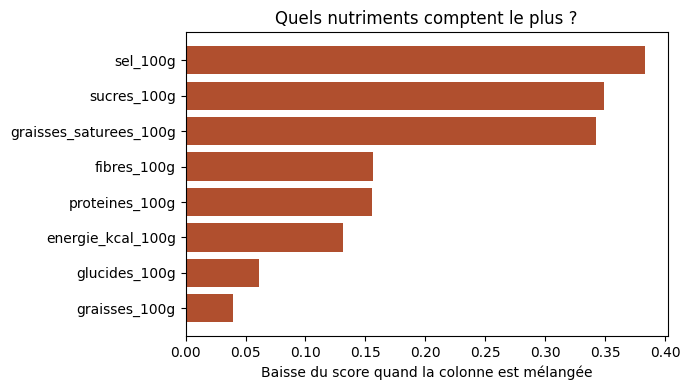

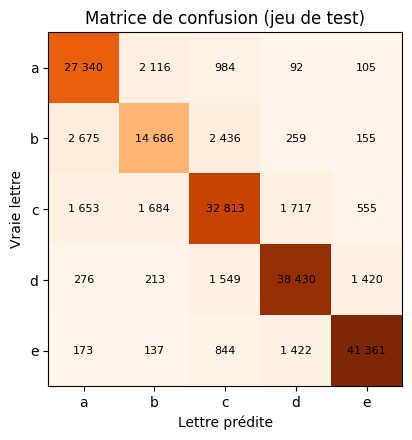

In [10]:
import matplotlib.pyplot as plt

# 1. Importance des nutriments
imp = importance.sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index, imp.values, color="#B04F2E")
ax.set_xlabel("Baisse du score quand la colonne est mélangée")
ax.set_title("Quels nutriments comptent le plus ?")
plt.tight_layout()
plt.savefig("../docs/ml_importance.png", dpi=150)
plt.show()

# 2. Matrice de confusion
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(matrice, cmap="Oranges")
ax.set_xticks(range(5)); ax.set_xticklabels(lettres)
ax.set_yticks(range(5)); ax.set_yticklabels(lettres)
ax.set_xlabel("Lettre prédite"); ax.set_ylabel("Vraie lettre")
ax.set_title("Matrice de confusion (jeu de test)")
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{matrice[i, j]:,}".replace(",", " "),
                ha="center", va="center", fontsize=8)
plt.tight_layout()
plt.savefig("../docs/ml_confusion.png", dpi=150)
plt.show()